# Лабораторная работа №2. СЛАУ: вариант н), II.10.5

$n=20$, главная диагональ — 10, соседние диагонали — 1, $b_i=i$.

![Система уравнений](data/s.png)

Все итерации начинаются с нуля. Остановка: $|b-Ax|_2/|b|_2\le10^{-10}$.

In [11]:
import numpy as np
import matplotlib.pyplot as plt

n = 20
A = 10*np.eye(n) + np.eye(n, k=1) + np.eye(n, k=-1)
b = np.arange(1, n + 1, dtype=float)

tol = 1e-10
max_iter = 10000

def relative_residual(A, b, x):
    scale = np.linalg.norm(b)
    if scale == 0:
        scale = 1.0
    return np.linalg.norm(b - A @ x) / scale

### 1. Гаусс с выбором главного элемента

In [12]:
def gauss(A, b):
    A = np.array(A, dtype=float, copy=True)
    b = np.array(b, dtype=float, copy=True)
    n = len(b)

    for k in range(n):
        p = k + np.argmax(np.abs(A[k:, k]))
        if A[p, k] == 0:
            raise ValueError("Матрица вырождена")

        A[[k, p]] = A[[p, k]]
        b[[k, p]] = b[[p, k]]

        for i in range(k + 1, n):
            factor = A[i, k] / A[k, k]
            A[i, k:] -= factor * A[k, k:]
            b[i] -= factor * b[k]

    x = np.zeros(n)
    for i in range(n - 1, -1, -1):
        x[i] = (b[i] - A[i, i + 1:] @ x[i + 1:]) / A[i, i]
    return x

### 2. LU-разложение
Решаем последовательно $Ly=b$, затем $Ux=y$.

In [13]:
def lu_solve(A, b):
    n = len(b)
    L = np.eye(n)
    U = np.zeros((n, n))

    for i in range(n):
        for j in range(i, n):
            U[i, j] = A[i, j] - L[i, :i] @ U[:i, j]

        if U[i, i] == 0:
            raise ValueError("LU без перестановок неприменимо")

        for j in range(i + 1, n):
            L[j, i] = (A[j, i] - L[j, :i] @ U[:i, i]) / U[i, i]

    y = np.zeros(n)
    for i in range(n):
        y[i] = b[i] - L[i, :i] @ y[:i]

    x = np.zeros(n)
    for i in range(n - 1, -1, -1):
        x[i] = (y[i] - U[i, i + 1:] @ x[i + 1:]) / U[i, i]
    return x

### 3–5. Якоби, Зейдель и верхняя релаксация
Якоби использует старые значения, Зейдель — уже обновлённые. Для SOR берём $\omega=1.1$.

In [14]:
def stationary(A, b, method, omega=1.1):
    n = len(b)
    x = np.zeros(n)
    history = [relative_residual(A, b, x)]

    if np.any(np.diag(A) == 0):
        raise ValueError("На диагонали есть нулевой элемент")

    for _ in range(max_iter):
        if history[-1] <= tol:
            break

        old = x.copy()
        for i in range(n):
            if method == "jacobi":
                left = A[i, :i] @ old[:i]
            else:
                left = A[i, :i] @ x[:i]

            right = A[i, i + 1:] @ old[i + 1:]
            value = (b[i] - left - right) / A[i, i]

            if method == "sor":
                x[i] = (1 - omega) * old[i] + omega * value
            else:
                x[i] = value

        history.append(relative_residual(A, b, x))
        if not np.isfinite(history[-1]):
            break
    return x, history

### 6–7. Градиентный спуск и минимальные невязки
Обновление $x\leftarrow x+\alpha r$, где $r=b-Ax$.
Спуск: $\alpha=(r^Tr)/(r^TAr)$; минимальные невязки: $\alpha=(r^TAr)/\|Ar\|^2$.

In [15]:
def descent(A, b, method):
    x = np.zeros(len(b))
    history = [relative_residual(A, b, x)]

    for _ in range(max_iter):
        if history[-1] <= tol:
            break

        r = b - A @ x
        Ar = A @ r

        if method == "gradient":
            denominator = r @ Ar
            if denominator <= 0:
                raise ValueError("Нарушено условие положительности")
            alpha = (r @ r) / denominator
        else:
            denominator = Ar @ Ar
            if denominator == 0:
                raise ValueError("Метод минимальных невязок остановился")
            alpha = (Ar @ r) / denominator

        x += alpha * r
        history.append(relative_residual(A, b, x))
        if not np.isfinite(history[-1]):
            break
    return x, history

### 8. Сопряжённые градиенты

In [16]:
def conjugate_gradient(A, b):
    x = np.zeros(len(b))
    r = b - A @ x
    p = r.copy()
    rr = r @ r
    history = [relative_residual(A, b, x)]

    for _ in range(max_iter):
        if history[-1] <= tol:
            break

        Ap = A @ p
        denominator = p @ Ap
        if denominator <= 0:
            raise ValueError("CG требует положительно определённую матрицу")

        alpha = rr / denominator
        x += alpha * p
        r -= alpha * Ap

        history.append(relative_residual(A, b, x))
        if history[-1] <= tol:
            break

        rr_new = r @ r
        if rr == 0:
            raise ValueError("Численный срыв CG")
        beta = rr_new / rr
        p = r + beta * p
        rr = rr_new
    return x, history

### 9. BiCGSTAB

In [17]:
def bicgstab(A, b):
    x = np.zeros(len(b))
    r = b - A @ x
    r_hat = r.copy()

    p = np.zeros_like(r)
    v = np.zeros_like(r)
    rho_old = alpha = omega = 1.0
    history = [relative_residual(A, b, x)]

    for k in range(max_iter):
        if history[-1] <= tol:
            break

        rho = r_hat @ r
        if rho == 0:
            raise ValueError("Численный срыв BiCGSTAB: rho = 0")

        if k == 0:
            p = r.copy()
        else:
            beta = (rho / rho_old) * (alpha / omega)
            p = r + beta * (p - omega * v)

        v = A @ p
        denominator = r_hat @ v
        if denominator == 0:
            raise ValueError("Численный срыв BiCGSTAB: r_hat @ v = 0")

        alpha = rho / denominator
        s = r - alpha * v

        candidate = x + alpha * p
        if relative_residual(A, b, candidate) <= tol:
            x = candidate
            history.append(relative_residual(A, b, x))
            break

        t = A @ s
        tt = t @ t
        if tt == 0:
            raise ValueError("Численный срыв BiCGSTAB: t @ t = 0")

        omega = (t @ s) / tt
        if omega == 0:
            raise ValueError("Численный срыв BiCGSTAB: omega = 0")

        x = candidate + omega * s
        r = s - omega * t
        rho_old = rho
        history.append(relative_residual(A, b, x))
    return x, history

### Сравнение
NumPy используется для проверки.

In [ ]:
x_ref = np.linalg.solve(A, b)

direct = {
    "Гаусс":    gauss(A, b),
    "LU":       lu_solve(A, b),
}
iterative = {
    "Якоби":                    stationary(A, b, "jacobi"),
    "Зейдель":                  stationary(A, b, "seidel"),
    "SOR, ω=1.1":               stationary(A, b, "sor", omega=1.1),
    "Градиентный спуск":        descent(A, b, "gradient"),
    "Минимальные невязки":      descent(A, b, "minres"),
    "Сопряжённые градиенты":    conjugate_gradient(A, b),
    "BiCGSTAB":                 bicgstab(A, b),
}

print("Решение:")
print(np.array2string(x_ref, precision=8))

print("\nПрямые методы:")
for name, x in direct.items():
    print(f"{name:25s} невязка = {relative_residual(A, b, x):.3e}")

print("\nИтерационные методы:")
for name, (x, history) in iterative.items():
    status = "сошёлся" if history[-1] <= tol else "не сошёлся"
    print(f"{name:25s} итераций = {len(history)-1:3d}, невязка = {history[-1]:.3e}, {status}")

Решение:
[0.08333333 0.16666667 0.25       0.33333333 0.41666667 0.5
 0.58333333 0.66666667 0.75       0.83333333 0.91666667 1.
 1.08333331 1.16666685 1.24999814 1.33335174 1.41648441 1.50180413
 1.56547433 1.84345257]

Прямые методы:
Гаусс                     невязка = 9.024e-17
LU                        невязка = 9.024e-17

Итерационные методы:
Якоби                     итераций =  15, невязка = 2.339e-11, сошёлся
Зейдель                   итераций =  10, невязка = 4.442e-11, сошёлся
SOR, ω=1.1                итераций =  14, невязка = 6.757e-11, сошёлся
Градиентный спуск         итераций =  13, невязка = 2.231e-11, сошёлся
Минимальные невязки       итераций =  13, невязка = 2.147e-11, сошёлся
Сопряжённые градиенты     итераций =  10, невязка = 3.165e-11, сошёлся
BiCGSTAB                  итераций =   6, невязка = 4.785e-11, сошёлся


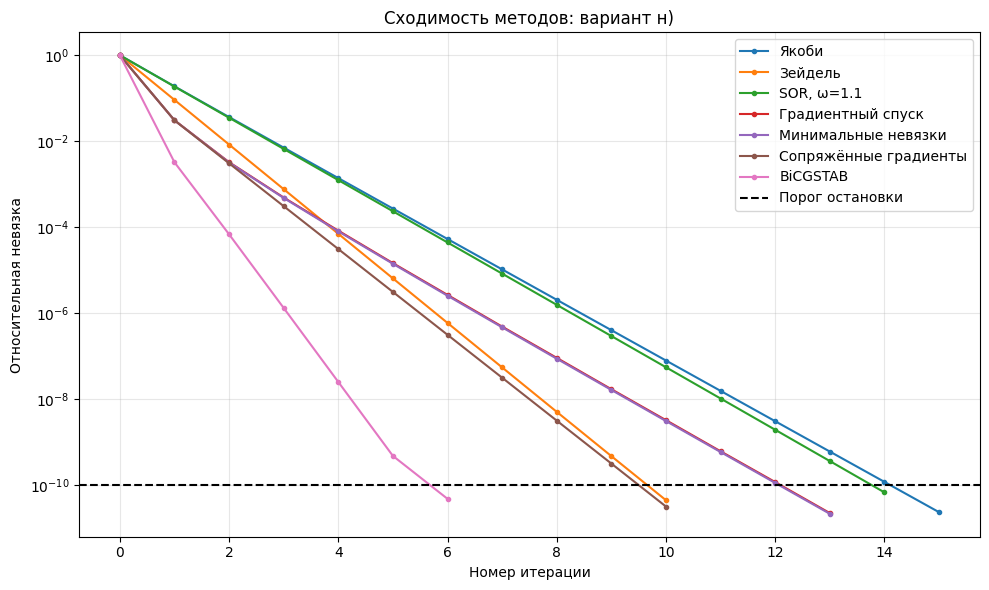

In [19]:
plt.figure(figsize=(10, 6))
for name, (x, history) in iterative.items():
    values = np.asarray(history)
    values = np.where(values > 0, values, np.nan)
    plt.semilogy(range(len(history)), values, ".-", label=name)

plt.axhline(tol, color="black", linestyle="--", label="Порог остановки")
plt.xlabel("Номер итерации")
plt.ylabel("Относительная невязка")
plt.title("Сходимость методов: вариант н)")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()